# **Práctica  3: Series de Fourier magnitud y fase.**
**Nombres:** Juliana Sarmiento Arciniegas y Valentina Restrepo.

## Resumen
En este laboratorio se realiza el análisis espectral y la reconstrucción de señales periódicas mediante la Serie Exponencial de Fourier, utilizando NumPy y Matplotlib (matplotlib.pyplot) en Python. En los incisos a y b, se realiza la construcción de las señales de prueba (cuadrada y triangular) mediante la definición de sus funciones y coeficientes analíticos de Fourier. En el inciso c, se grafican ambas señales continuas e ideales en el dominio del tiempo.   A continuación, se desarrolla una función en Python para calcular numéricamente los coeficientes de Fourier $c_k$ mediante la Transformada Rápida de Fourier (FFT), graficando sus espectros de magnitud y fase. Posteriormente, se evalúa la convergencia de la reconstrucción al truncar la serie en $N \in \{1, 3, 5, 20, 50\}$ armónicos, analizando el fenómeno de Gibbs que surge en la onda cuadrada por sus discontinuidades. Finalmente, se examina la composición espectral de una señal electrocardiográfica (ECG) limpia, vinculando la distribución de frecuencias de sus armónicos con los eventos fisiológicos del ciclo cardíaco (ondas P, T y complejo QRS).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

**Generación de Señales Cuadrada y Triangular desde el Dominio de la Frecuencia**

Definimos los parámetros fundamentales de la señal: amplitud $A=1.0$, frecuencia fundamental $f_0=1\text{ Hz}$ ($T_0=1\text{ s}$) y número de muestras $N=1000$. Para construir la señal desde su representación analítica de Fourier, creamos una función que calcula sus coeficientes complejos $c_k$, teniendo en cuenta que una onda cuadrada simétrica solo posee armónicos impares dados por $c_k = \frac{-j 2 A}{k \pi}$ para $k$ impar. 

In [11]:
# Parámetros compartidos para las señales
A = 1.0           # Amplitud
f0 = 1.0          # Frecuencia fundamental (Hz)
T0 = 1 / f0       # Período (s)
N = 1000          # Número de muestras por período
K_sintesis = 200  # Número de armónicos para la representación

# Vector de tiempo discreto para un período
n = np.arange(N)
t = n * (T0 / N)

# Inciso a: Función para generar los coeficientes c_k analíticos de la señal cuadrada
def generar_coeficientes_cuadrada(A, K):
    k_vals = np.arange(-K, K + 1)
    c_k = np.zeros(len(k_vals), dtype=complex)
    for i, k in enumerate(k_vals):
        if k != 0 and k % 2 != 0: # Solo armónicos impares
            c_k[i] = -1j * (2 * A) / (k * np.pi)
    return k_vals, c_k

# Generar coeficientes de la señal cuadrada
k_cuad_teorico, c_k_cuad_teorico = generar_coeficientes_cuadrada(A, K_sintesis)

Construimos la señal triangular respetando la misma frecuencia fundamental, amplitud y número de muestras que la señal cuadrada. De igual manera, creamos la función que calcula sus coeficientes analíticos de Fourier $c_k = \frac{2 A}{(k \pi)^2} (1 - (-1.0)^k)$ para $k$ impar. Se utiliza -1.0 en flotante para garantizar la compatibilidad con potencias de exponentes negativos en Python. 

In [12]:
# Inciso b: Función para generar los coeficientes c_k analíticos de la señal triangular
def generar_coeficientes_triangular(A, K):
    k_vals = np.arange(-K, K + 1)
    c_k = np.zeros(len(k_vals), dtype=complex)
    for i, k in enumerate(k_vals):
        if k != 0 and k % 2 != 0: # Solo armónicos impares
            c_k[i] = (2 * A) / ((k * np.pi)**2) * (1 - (-1.0)**k)
    return k_vals, c_k

# Generar coeficientes de la señal triangular
k_tri_teorico, c_k_tri_teorico = generar_coeficientes_triangular(A, K_sintesis)

Para obtener las trazados ideales, limpios y continuos (sin el rizado del fenómeno de Gibbs que produce la sumatoria de Fourier), definimos las señales directamente mediante sus ecuaciones continuas en el tiempo (np.where para la cuadrada y la función de rampa para la triangular). A continuación, las graficamos superpuestas en una misma figura sobre un período completo ($T_0 = 1\text{ s}$) utilizando únicamente comandos directos de matplotlib.pyplot (plt).

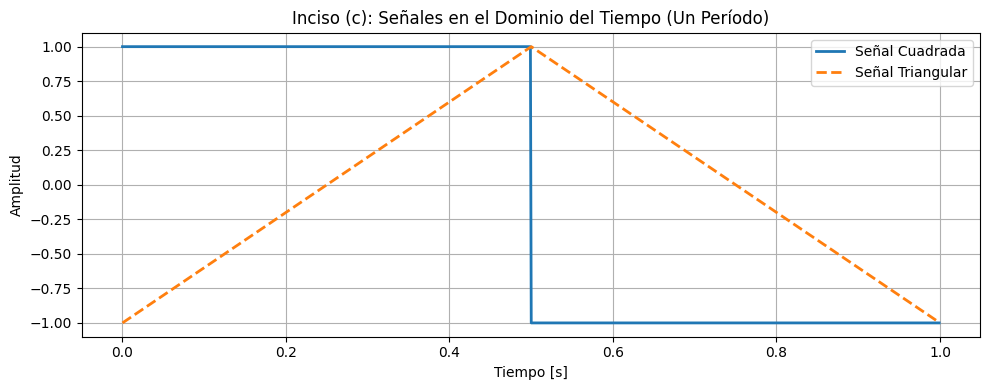

In [13]:
# Inciso c: Construcción de señales continuas e ideales en el tiempo
x_cuadrada_lisa = np.where(t < T0 / 2, A, -A)
x_triangular_lisa = A * (1 - 4 * np.abs(t / T0 - 0.5))

# Gráfica comparativa en el dominio del tiempo
plt.figure(figsize=(10, 4))
plt.plot(t, x_cuadrada_lisa, label='Señal Cuadrada', color='tab:blue', linewidth=2)
plt.plot(t, x_triangular_lisa, label='Señal Triangular', color='tab:orange', linewidth=2, linestyle='--')
plt.title('Inciso (c): Señales en el Dominio del Tiempo (Un Período)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Función para Coeficientes de Fourier con NumPy, punto d y e:**

Desarrollamos la función calcular_coeficientes_fourier(x) que toma como entrada una señal discreta en el tiempo $x[n]$ y obtiene sus coeficientes exponenciales $c_k$ mediante la Transformada Rápida de Fourier (np.fft.fft). Dividimos el resultado por $N$ para ajustar la escala de amplitud a los coeficientes reales y utilizamos np.fft.fftshift para reordenar el vector, colocando la componente continua ($c_0$) en el centro del arreglo de frecuencias.

In [ ]:
# d: Función en Python para calcular los coeficientes c_k con NumPy
def calcular_coeficientes_fourier(x):
    """
    Recibe una señal periódica discreta x[n] y devuelve los índices de armónicos k
    junto con sus coeficientes complejos c_k calculados mediante FFT.
    """
    N = len(x)
    c_k = np.fft.fft(x) / N  # FFT escalada por N
    
    c_k_shifted = np.fft.fftshift(c_k) # Centrar k = 0
    k = np.arange(-N//2, N//2)
    
    return k, c_k_shifted

**Espectros de Magnitud y Fase, punto f y g**

Aplicamos la función del inciso d sobre las señales temporales x_cuadrada_lisa y x_triangular_lisa (e). Luego definimos la función graficar_espectros (f) para representar el espectro de magnitud $\vert{}c_k\vert{}$ y el espectro de fase $\arg(c_k)$ mediante plt.subplot y plt.stem (g). Para limpiar la visualización, fijamos la fase en $0\text{ rad}$ para aquellas componentes con magnitud insignificante ($< 10^{-4}$).  

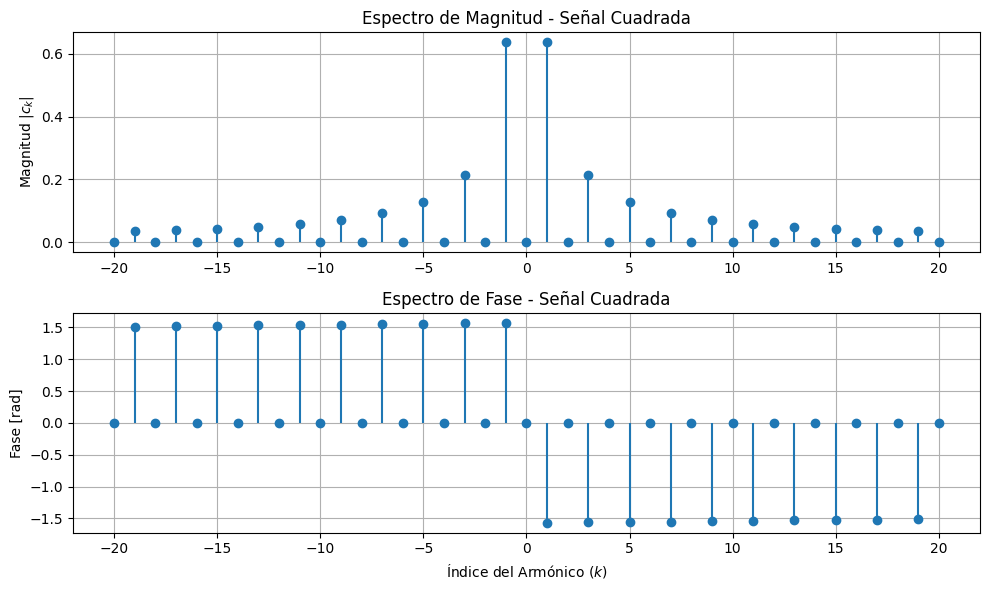

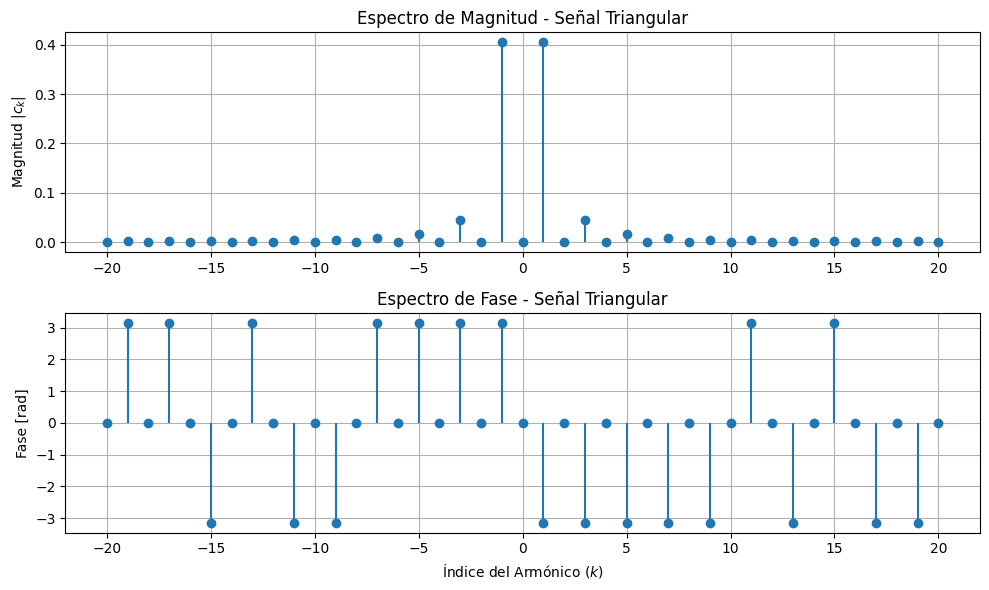

In [16]:
# e: Calcular coeficientes con NumPy
k_cuad_num, c_k_cuad_num = calcular_coeficientes_fourier(x_cuadrada_lisa)
k_tri_num, c_k_tri_num = calcular_coeficientes_fourier(x_triangular_lisa)

# f: Función para graficar espectros de magnitud y fase usando plt
def graficar_espectros(k, c_k, titulo, max_k=20):
    mask = np.abs(k) <= max_k
    k_sub = k[mask]
    c_sub = c_k[mask]
    
    magnitud = np.abs(c_sub)
    fase = np.angle(c_sub)
    fase[magnitud < 1e-4] = 0.0

    plt.figure(figsize=(10, 6))
    
    # Espectro de Magnitud
    plt.subplot(2, 1, 1)
    plt.stem(k_sub, magnitud, basefmt=" ")
    plt.title(f'Espectro de Magnitud - {titulo}')
    plt.ylabel('Magnitud $|c_k|$')
    plt.grid(True)
    
    # Espectro de Fase
    plt.subplot(2, 1, 2)
    plt.stem(k_sub, fase, basefmt=" ")
    plt.title(f'Espectro de Fase - {titulo}')
    plt.xlabel('Índice del Armónico ($k$)')
    plt.ylabel('Fase [rad]')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

# g: Graficar espectros numéricos
graficar_espectros(k_cuad_num, c_k_cuad_num, "Señal Cuadrada", max_k=20)
graficar_espectros(k_tri_num, c_k_tri_num, "Señal Triangular", max_k=20)

**Reconstrucción de la Señal y Fenómeno de Gibbs puntos h e i**

Creamos la función de reconstrucción truncada (inciso h) y graficamos la aproximación temporal producida al utilizar únicamente $N \in \{1, 3, 5, 20, 50\}$ armónicos mediante plt.subplot (inciso i).   En la respuesta del inciso j, analizamos el comportamiento de ambas reconstrucciones:   La onda triangular es continua, por lo que sus coeficientes decrecen rápidamente ($\sim 1/k^2$) y converge de forma uniforme y limpia a la señal original con pocos armónicos.   La onda cuadrada contiene discontinuidades de salto, lo que desencadena el fenómeno de Gibbs. Al intentar formar bordes verticales mediante una suma finita de exponenciales o senos continuos, se generan rizos y sobrepicos característicos en los bordes. A medida que el número de armónicos aumenta a $N=50$, las oscilaciones se comprimen hacia el salto, pero su amplitud máxima no se elimina, estabilizándose en un sobrepico de aproximadamente 9% respecto a la altura de la discontinuidad

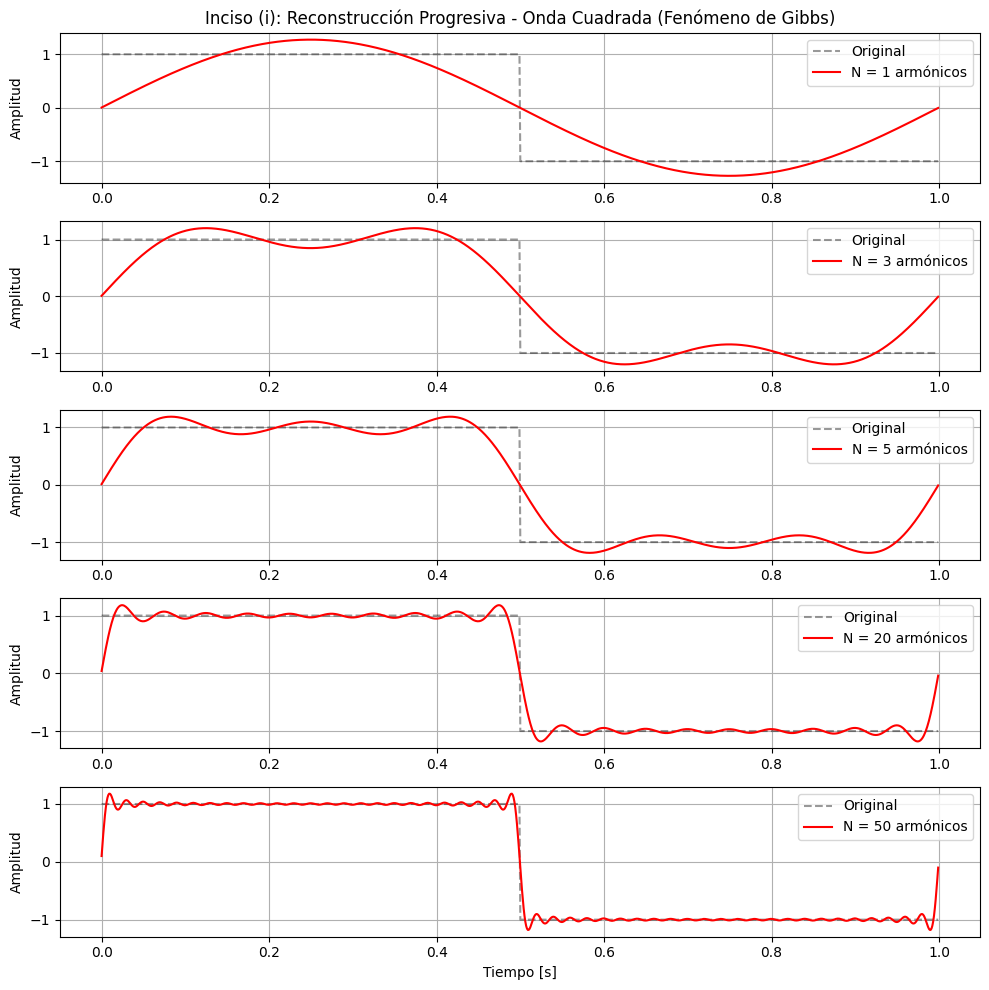

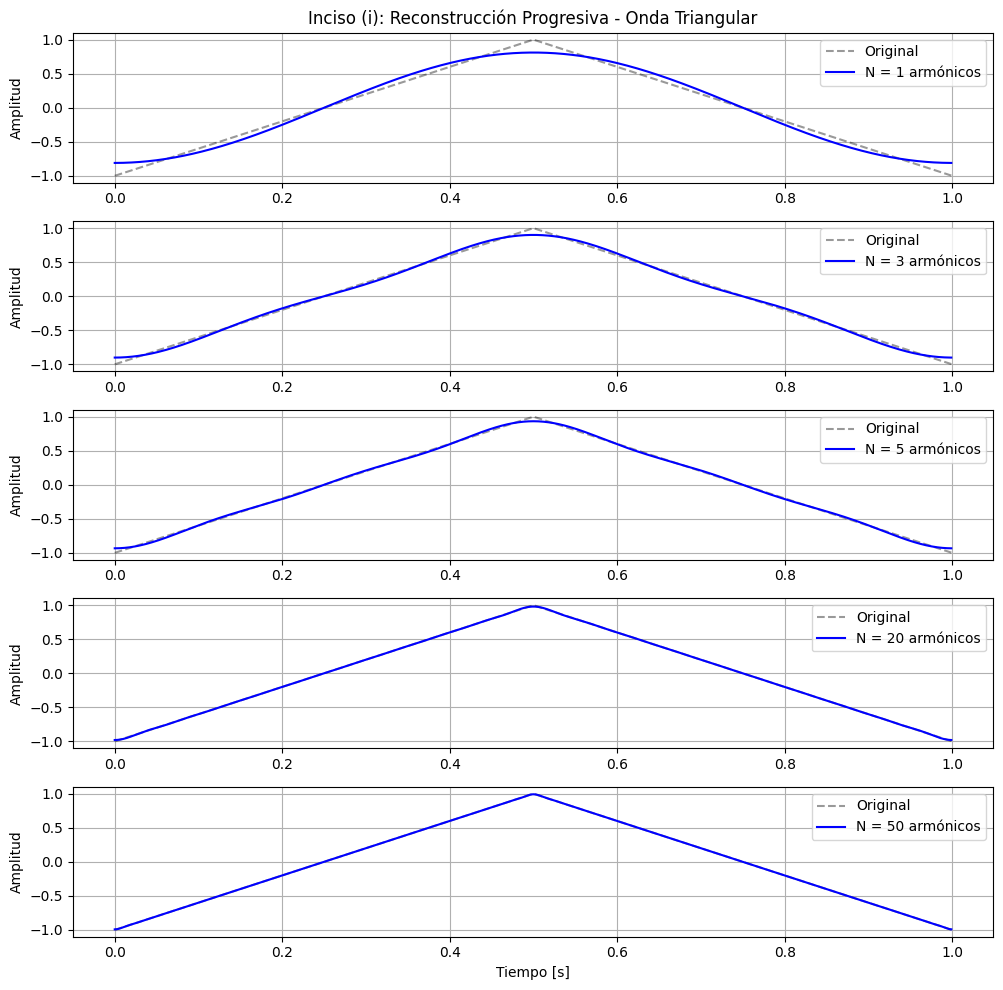

In [17]:
# h: Función de reconstrucción limitada a K armónicos
def reconstruir_senal(c_k, k, K, N):
    n = np.arange(N)
    x_rec = np.zeros(N, dtype=complex)
    mask = (k >= -K) & (k <= K)
    k_sel = k[mask]
    c_sel = c_k[mask]
    
    for k_val, c_val in zip(k_sel, c_sel):
        x_rec += c_val * np.exp(1j * 2 * np.pi * k_val * n / N)
        
    return x_rec.real

# i: Reconstrucciones progresivas con N_armonicos = [1, 3, 5, 20, 50]
armónicos_list = [1, 3, 5, 20, 50]

# Reconstrucción Onda Cuadrada (Evidencia del fenómeno de Gibbs)
plt.figure(figsize=(10, 10))
for i, K in enumerate(armónicos_list):
    x_rec = reconstruir_senal(c_k_cuad_num, k_cuad_num, K, N)
    plt.subplot(len(armónicos_list), 1, i + 1)
    plt.plot(t, x_cuadrada_lisa, 'k--', alpha=0.4, label='Original')
    plt.plot(t, x_rec, 'r', label=f'N = {K} armónicos')
    plt.ylabel('Amplitud')
    plt.grid(True)
    plt.legend(loc='upper right')
    if i == 0:
        plt.title('Inciso (i): Reconstrucción Progresiva - Onda Cuadrada (Fenómeno de Gibbs)')

plt.xlabel('Tiempo [s]')
plt.tight_layout()
plt.show()

# Reconstrucción Onda Triangular
plt.figure(figsize=(10, 10))
for i, K in enumerate(armónicos_list):
    x_rec = reconstruir_senal(c_k_tri_num, k_tri_num, K, N)
    plt.subplot(len(armónicos_list), 1, i + 1)
    plt.plot(t, x_triangular_lisa, 'k--', alpha=0.4, label='Original')
    plt.plot(t, x_rec, 'b', label=f'N = {K} armónicos')
    plt.ylabel('Amplitud')
    plt.grid(True)
    plt.legend(loc='upper right')
    if i == 0:
        plt.title('Inciso (i): Reconstrucción Progresiva - Onda Triangular')

plt.xlabel('Tiempo [s]')
plt.tight_layout()
plt.show()

**Simulación/Carga de Señal ECG y Análisis Espectral, punto k**

Sintetizamos un ciclo de electrocardiograma (ECG) cuasi-periódico limpio a una frecuencia de muestreo de $f_s = 500\text{ Hz}$ y calculamos su espectro mediante la función desarrollada en el inciso d. Al representar la magnitud $\vert{}c_k\vert{}$ en función de la frecuencia real en Hertz, vinculamos los eventos cardíacos con su contenido en el dominio frecuencial:   Onda P (Despolarización Auricular): Es una deflexión suave y de baja frecuencia, correspondiente a la banda de 0.5 Hz – 10 Hz.   Complejo QRS (Despolarización Ventricular): Representa el evento de mayor pendiente y cambio rápido de voltaje en el tiempo. Demanda componentes de frecuencia más alta (10 Hz – 40 Hz), con una concentración máxima cerca de los 15 Hz.   Onda T (Repolarización Ventricular): Corresponde a una deflexión ancha y lenta, ocupando el rango de 0.5 Hz – 7 Hz.

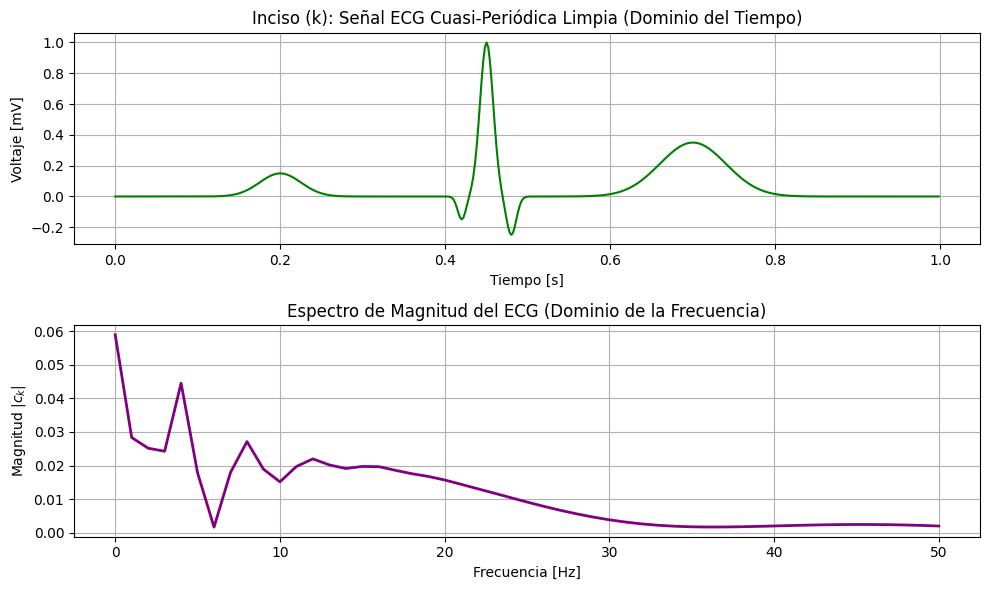

In [18]:
#k: Generación y análisis espectral de ECG sintético
fs_ecg = 500
t_ecg = np.linspace(0, 1, fs_ecg, endpoint=False)

onda_P   =  0.15 * np.exp(-((t_ecg - 0.20)**2) / (2 * 0.025**2))
comp_QRS = -0.15 * np.exp(-((t_ecg - 0.42)**2) / (2 * 0.005**2)) \
           + 1.00 * np.exp(-((t_ecg - 0.45)**2) / (2 * 0.008**2)) \
           - 0.25 * np.exp(-((t_ecg - 0.48)**2) / (2 * 0.006**2))
onda_T   =  0.35 * np.exp(-((t_ecg - 0.70)**2) / (2 * 0.040**2))

ecg_signal = onda_P + comp_QRS + onda_T

# Espectro del ECG mediante la función del inciso d
k_ecg, c_k_ecg = calcular_coeficientes_fourier(ecg_signal)
freqs = k_ecg * (fs_ecg / len(ecg_signal)) # Conversión a Frecuencia en Hz

# Gráfica del ECG en tiempo y espectro de magnitud
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(t_ecg, ecg_signal, color='green', linewidth=1.5)
plt.title('Inciso (k): Señal ECG Cuasi-Periódica Limpia (Dominio del Tiempo)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Voltaje [mV]')
plt.grid(True)

plt.subplot(2, 1, 2)
mask_freq = (freqs >= 0) & (freqs <= 50)
plt.plot(freqs[mask_freq], np.abs(c_k_ecg[mask_freq]), color='purple', linewidth=2)
plt.title('Espectro de Magnitud del ECG (Dominio de la Frecuencia)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud $|c_k|$')
plt.grid(True)

plt.tight_layout()
plt.show()

## Conclusiones:
*  Las señales continuas como la onda triangular concentran la mayor parte de su energía en armónicos de bajo orden ($\sim 1/k^2$), permitiendo una reconstrucción fiel con pocos términos. En cambio, señales con saltos abruptos como la onda cuadrada requieren una contribución prolongada de armónicos de alta frecuencia ($\sim 1/k$).   
*  En presencia de discontinuidades de salto, la serie de Fourier truncada siempre presenta un sobrepico no nulo del ~9% cerca de los bordes, demostrando que aumentar el número de armónicos $N$ reduce el ancho de la oscilación pero no su altura.   
* El desglose espectral confirma que los cambios rápidos de voltaje (complejo QRS) demandan frecuencias de hasta 40 Hz, mientras que las ondas P y T operan por debajo de los 10 Hz. Esto justifica el uso de filtros pasa-banda biomédicos para atenuar ruido e interferencia de la red eléctrica (60 Hz) sin distorsionar la amplitud ni la pendiente del complejo QRS. 